# 实验01：SVD及其应用

这是已执行的结果浏览笔记本。所有表格读取真实运行产物，图像来自同目录 results。完整算法见 run_experiment.py。

重新计算全部实验：取消下一单元格末尾两行的注释。

In [1]:
from pathlib import Path
import json, csv
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if not (ROOT / "results").exists():
    ROOT=ROOT / "实验01_SVD及其应用" / "02_实验本体"
OUT=ROOT / "results"
def show_json(name):
    display(json.loads((OUT/name).read_text()))
def show_image(name):
    display(Image(filename=str(OUT/name),width=850))
# import run_experiment
# run_experiment.main()

## 1. 给定矩阵
A=Q5 @ Sigma @ Q4；Q4 代表 Vᵀ。注意六位小数舍入与奇异向量成对变号。

In [2]:
show_json("matrix_summary.json")

{'assembly': 'Q5 @ Sigma @ Q4 (Q4 represents Vt)',
 'transpose_candidate_vs_printed_max_abs': 41.70065820844961,
 'printed_A_singular_values': [100.0000004392112,
  10.000000129981517,
  0.10000009400528806,
  0.0010000917953630316],
 'rank': 4,
 'singular_values': [100.0000153190884,
  10.000004985636672,
  0.09999993407793366,
  0.0009999994448259466],
 'condition_number': 100000.07083653308,
 'Q5_orthogonality_error': 2.2837774806002733e-06,
 'Q4_orthogonality_error': 2.1757590504794112e-06,
 'assembled_vs_printed_max_abs': 3.275829229920646e-05,
 'assembled_vs_printed_relative': 7.681704158643849e-07,
 'reconstruction_error': 5.974591220920224e-14,
 'eigen_implementation_max_s_error': 5.486896072041947e-11,
 'energy': [{'k': 1,
   'energy': 0.9900980227381365,
   'relative_error': 0.0995086793293097,
   'tail_error': 10.000505022226266},
  {'k': 2,
   'energy': 0.9999990098045763,
   'relative_error': 0.0009950856363483954,
   'tail_error': 0.1000049339506843},
  {'k': 3,
   'energ

## 2. 灰度及RGB重建
三通道指标按奇异值尾和合计，裁剪仅用于显示。

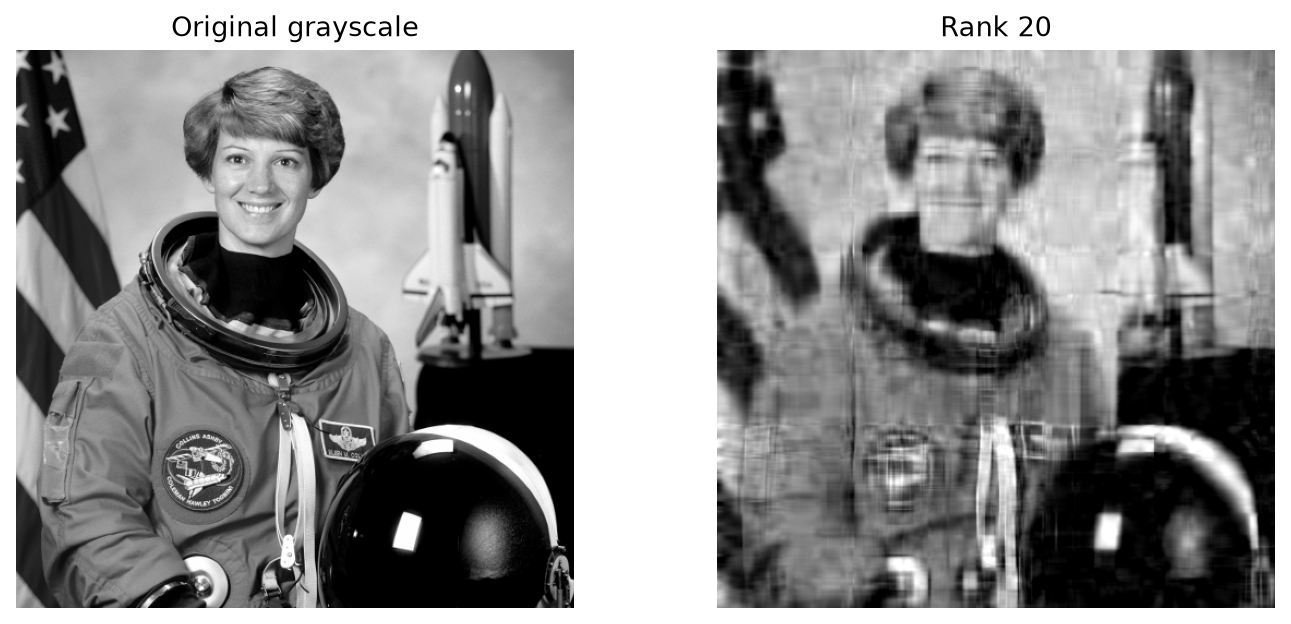

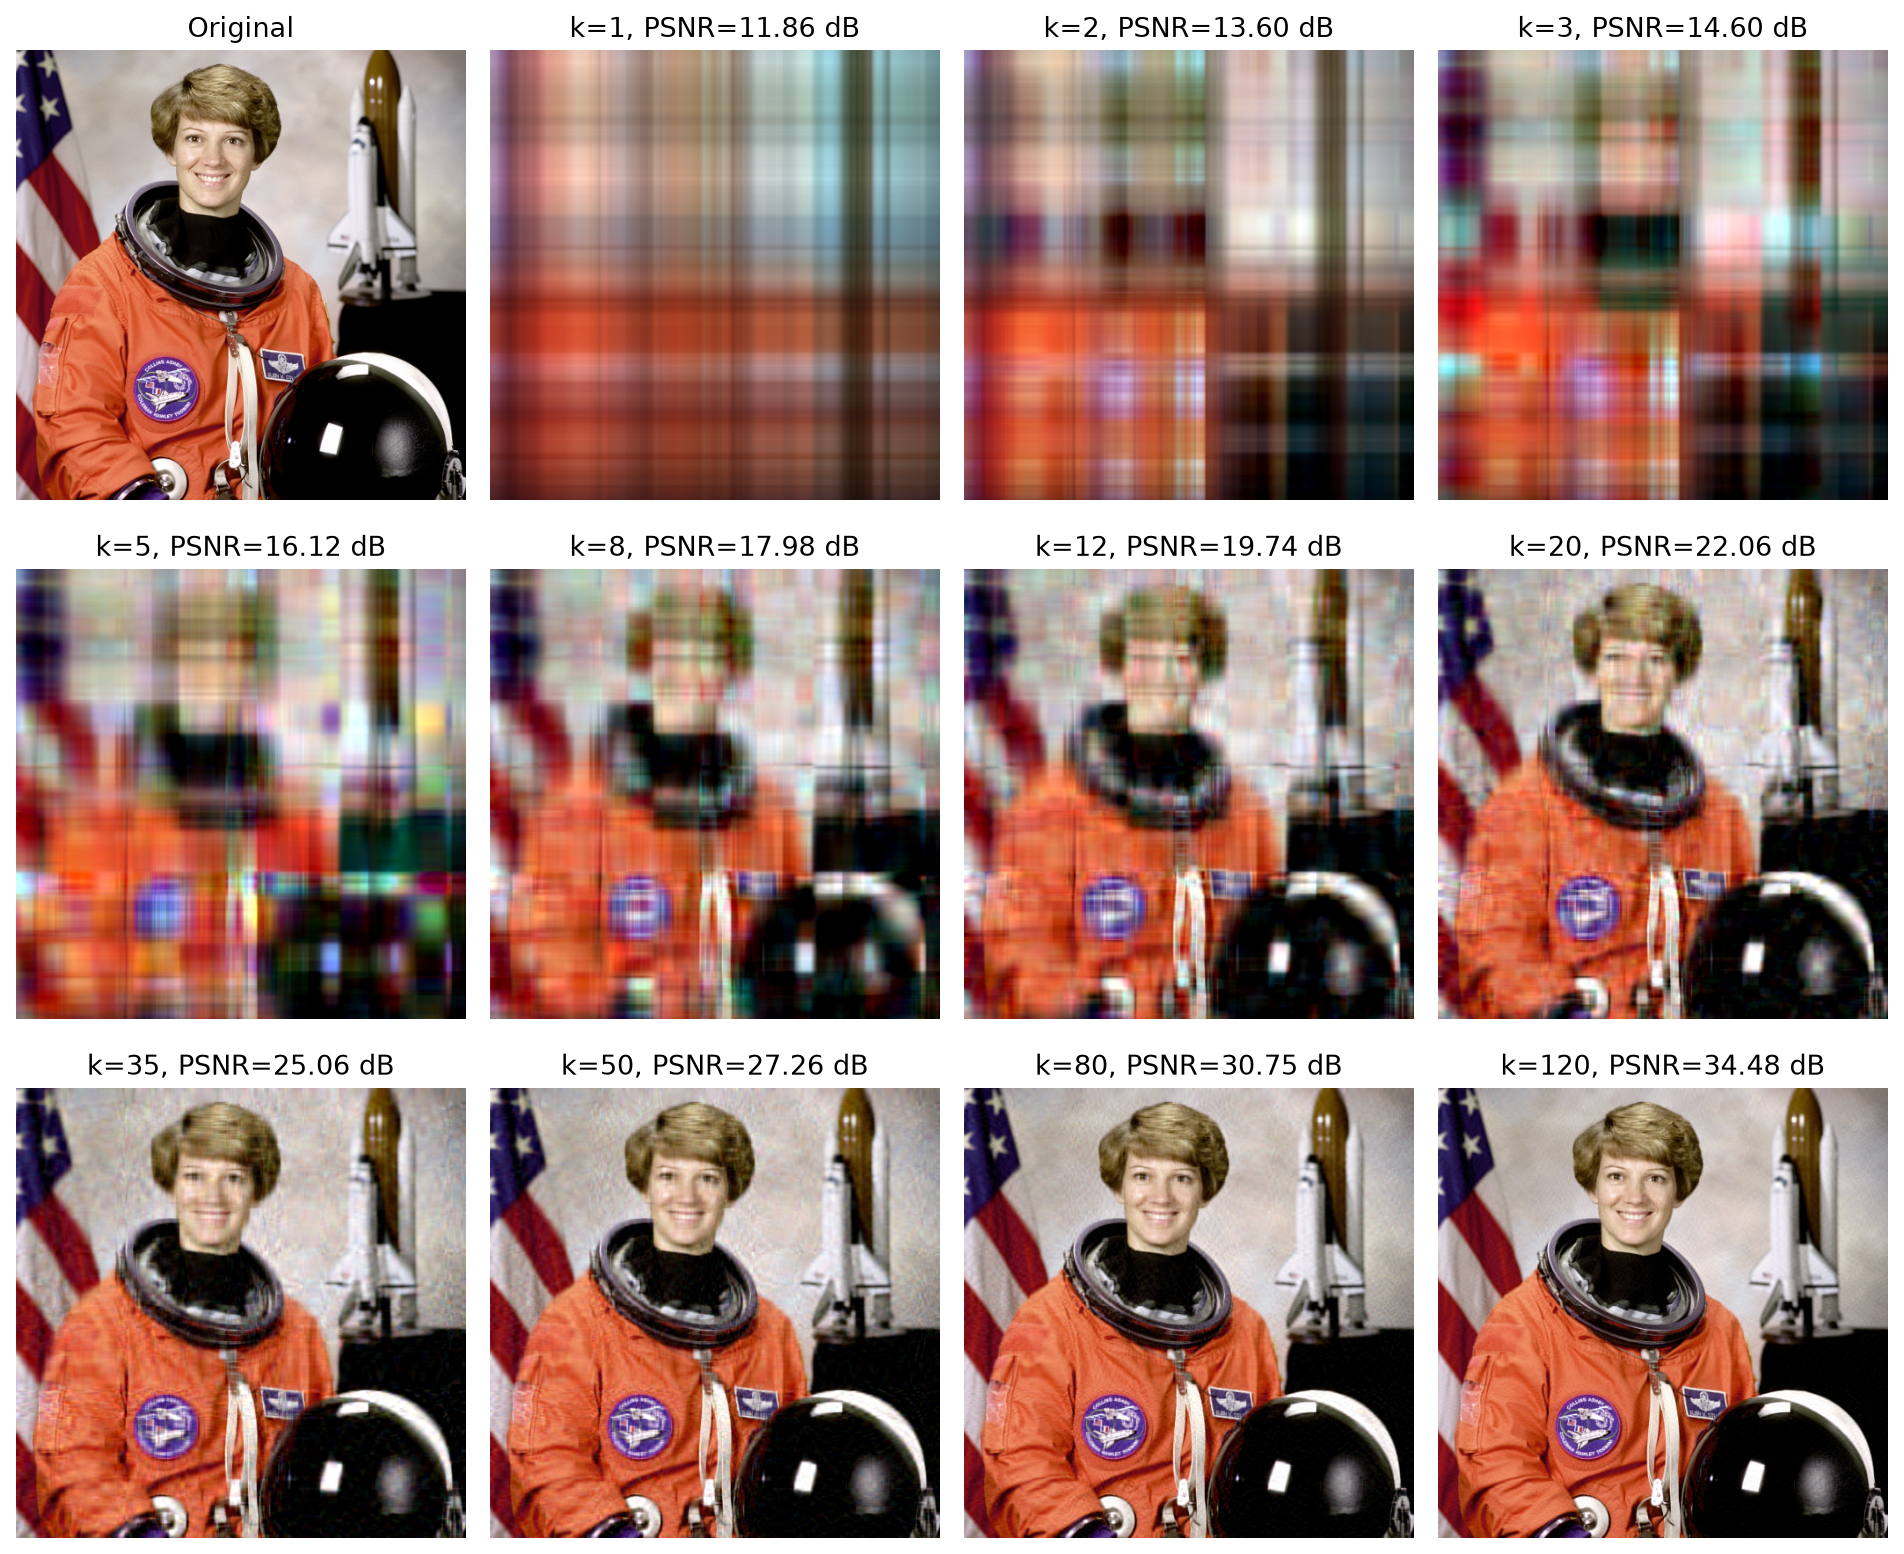

{'shape': [512, 512, 3],
 'grayscale_rank20_shape': [512, 512],
 'kstar': 255.75024390243902,
 'first_expansion_k': 256,
 'selected': [{'k': 1,
   'parameters': 3075,
   'compression_ratio': 255.75024390243902,
   'relative_error': 0.4636193296665768,
   'mse': 0.06522265943469505,
   'psnr_db': 11.856014969396636,
   'energy': 0.785057117159514},
  {'k': 4,
   'parameters': 12300,
   'compression_ratio': 63.937560975609756,
   'relative_error': 0.30730140743685397,
   'mse': 0.02865527180988624,
   'psnr_db': 15.427954676817556,
   'energy': 0.9055658449873287},
  {'k': 20,
   'parameters': 61500,
   'compression_ratio': 12.787512195121952,
   'relative_error': 0.14318764757192848,
   'mse': 0.0062213773239433515,
   'psnr_db': 22.06113458079116,
   'energy': 0.9794972975828172},
  {'k': 35,
   'parameters': 107625,
   'compression_ratio': 7.307149825783972,
   'relative_error': 0.10142824699030296,
   'mse': 0.0031217151547568087,
   'psnr_db': 25.0560672727009,
   'energy': 0.989712

In [3]:
show_image("01_grayscale_rank20.png")
show_image("02_rgb_rank_grid.png")
show_json("image_summary.json")

## 3. 完整指标与曲线
image_metrics_all_k.csv 包含 k=1 至 512 的全部行。

完整指标行数： 512


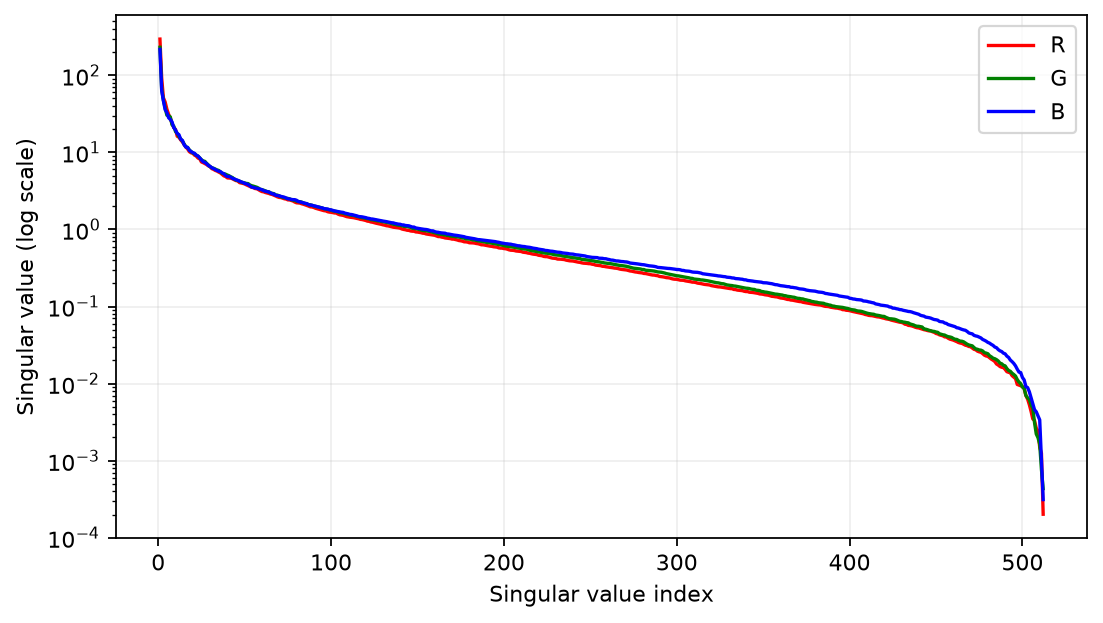

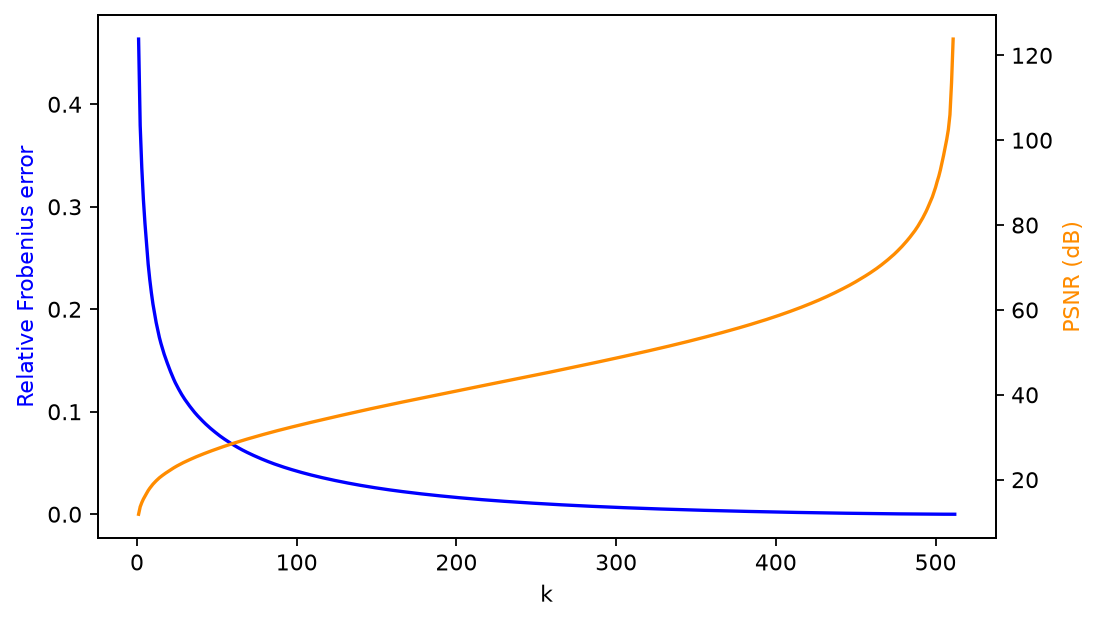

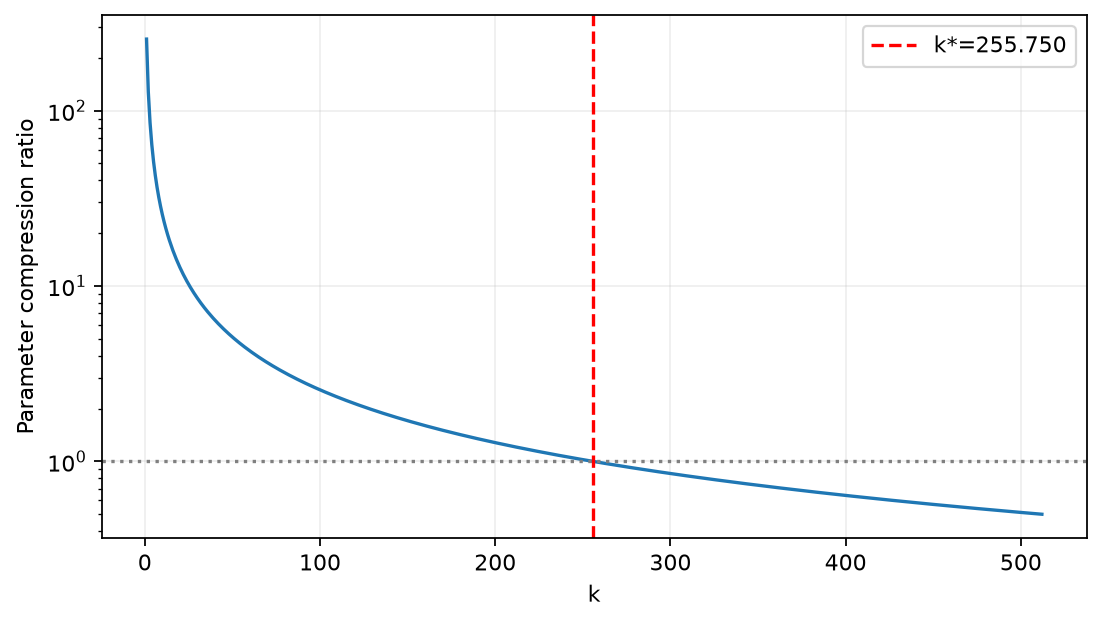

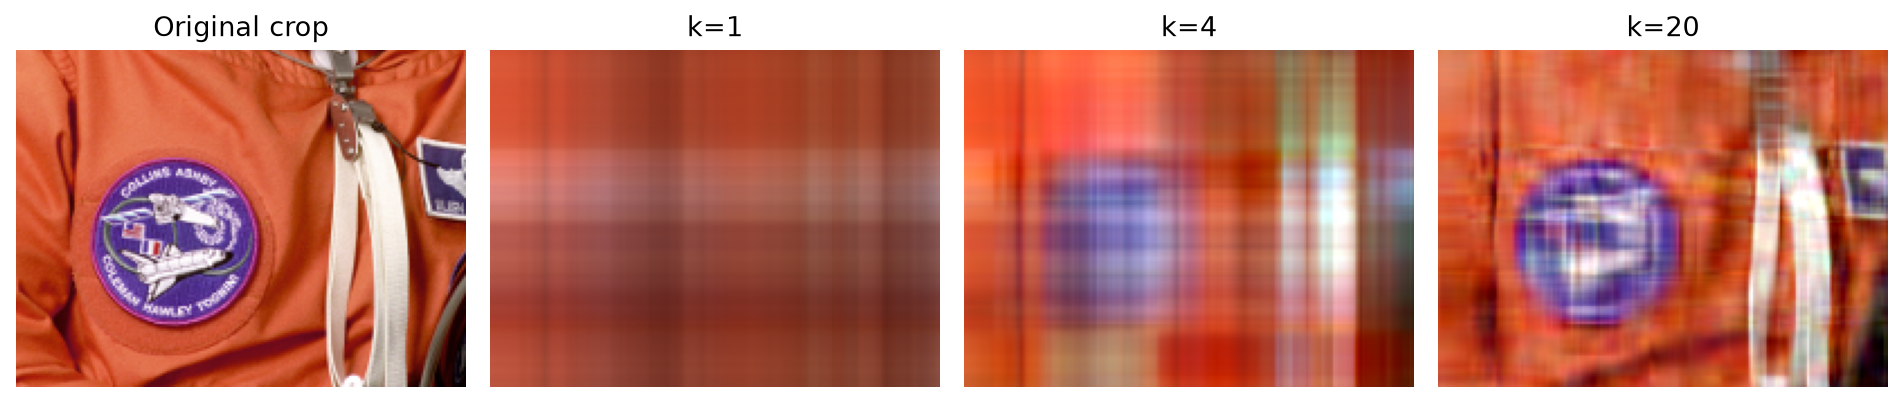

In [4]:
with (OUT/"image_metrics_all_k.csv").open(encoding="utf-8-sig") as fh:
    metrics=list(csv.DictReader(fh))
print("完整指标行数：",len(metrics))
assert len(metrics)==512
for name in ["03_singular_values.png","04_error_psnr.png","05_compression_ratio.png","06_detail_crop.png"]:
    show_image(name)

## 4. Eigenfaces
固定训练/测试划分，不用测试照片拟合基。单次闭集评估不代表对未知身份的识别。

{'seed': 20260917,
 'people': 40,
 'images': 400,
 'dimensions': 10304,
 'training_images': 280,
 'test_images': 120,
 'primary_k': 80,
 'primary_accuracy': 0.9833333333333333,
 'primary_correct': 118,
 'wilson_95': [0.9412640370278428, 0.9954174354340787],
 'metrics': [{'k': 1,
   'correct': 9,
   'test_count': 120,
   'accuracy': 0.075,
   'test_mse': 0.01977729354894186,
   'test_psnr_db': 17.03833140301065,
   'training_centered_energy': 0.17320636909198972,
   'train_library_parameter_ratio': 138.12332439678283},
  {'k': 2,
   'correct': 41,
   'test_count': 120,
   'accuracy': 0.3416666666666667,
   'test_mse': 0.017076306412694465,
   'test_psnr_db': 17.676060609336524,
   'training_centered_energy': 0.3089458967241309,
   'train_library_parameter_ratio': 91.67259786476869},
  {'k': 5,
   'correct': 99,
   'test_count': 120,
   'accuracy': 0.825,
   'test_mse': 0.012908171890898209,
   'test_psnr_db': 18.89135259973158,
   'training_centered_energy': 0.4832213724337817,
   'trai

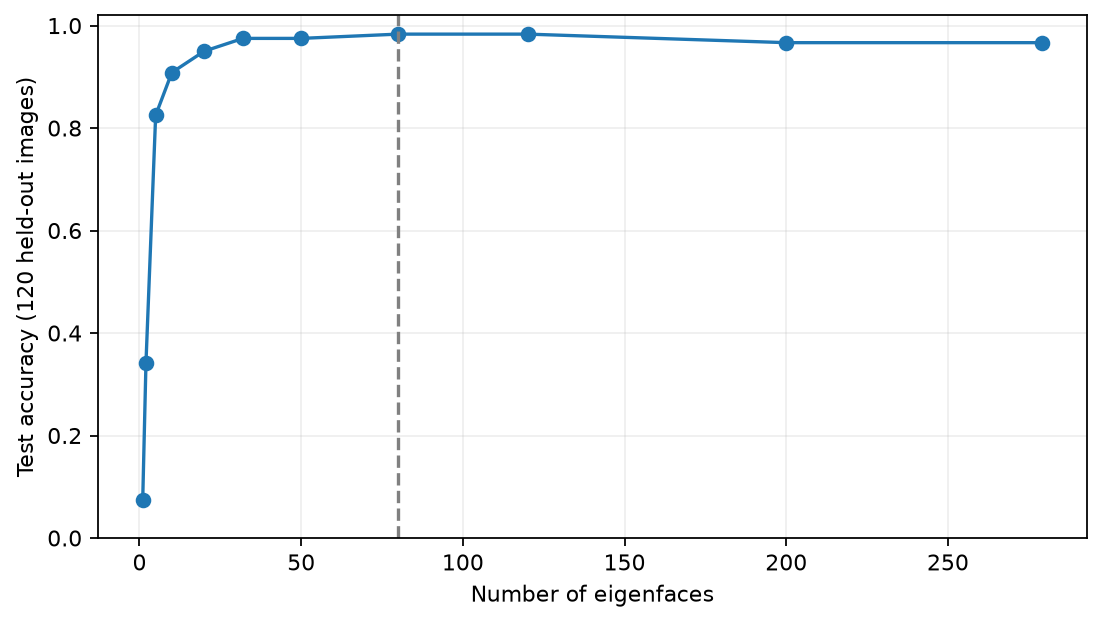

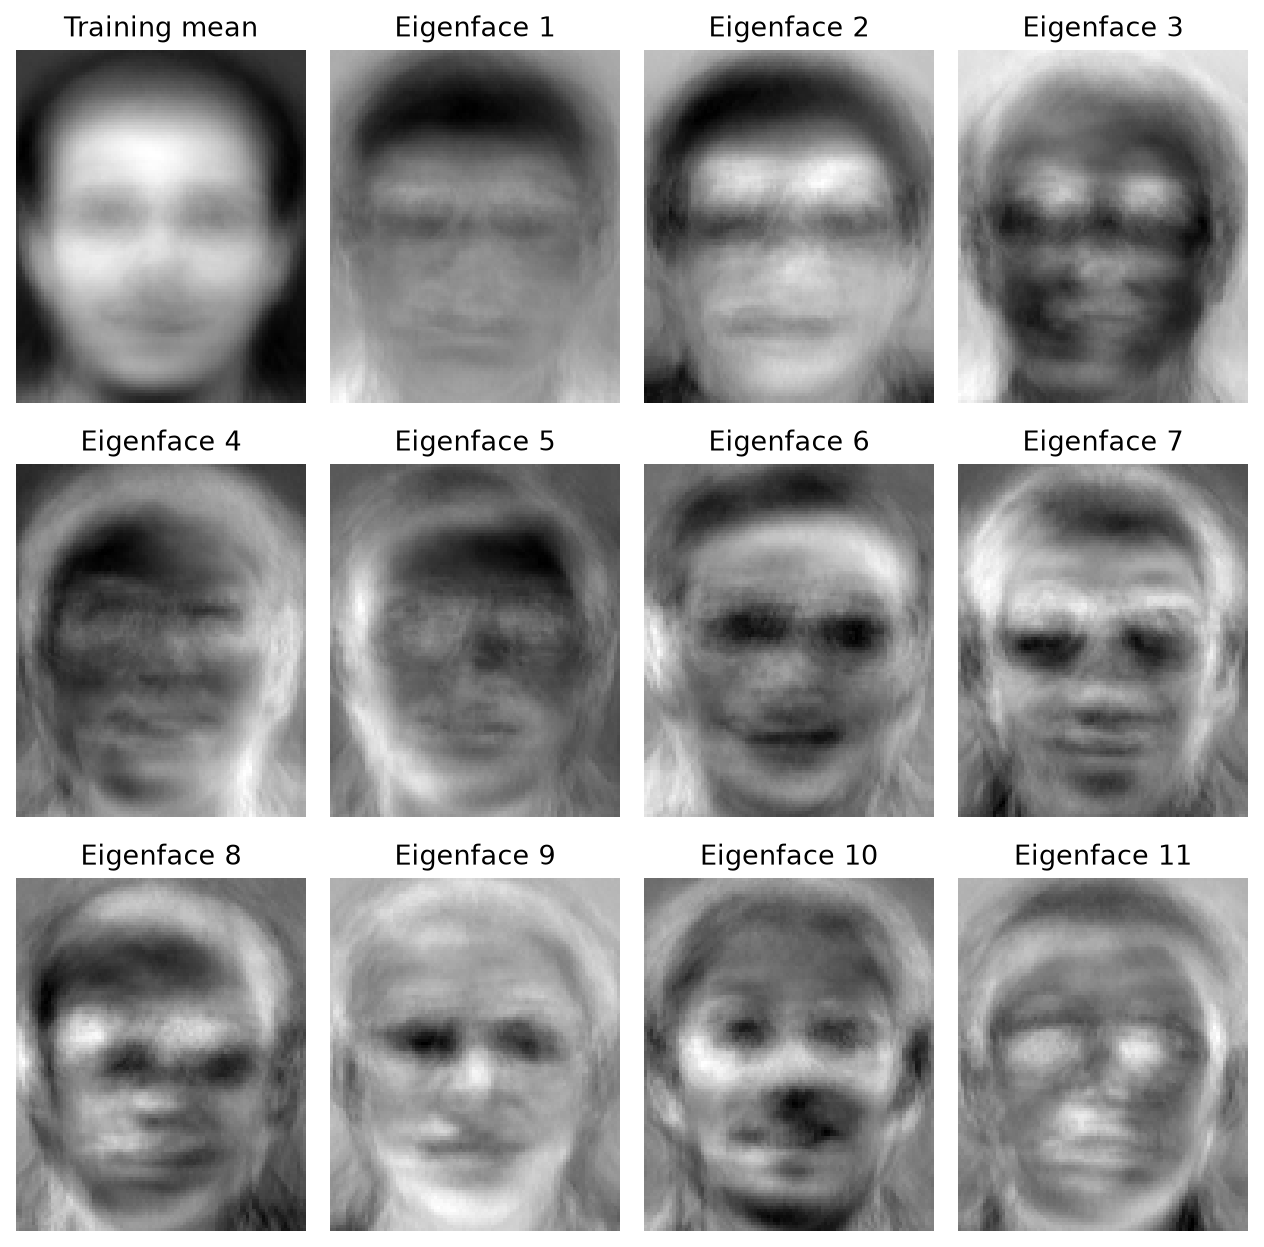

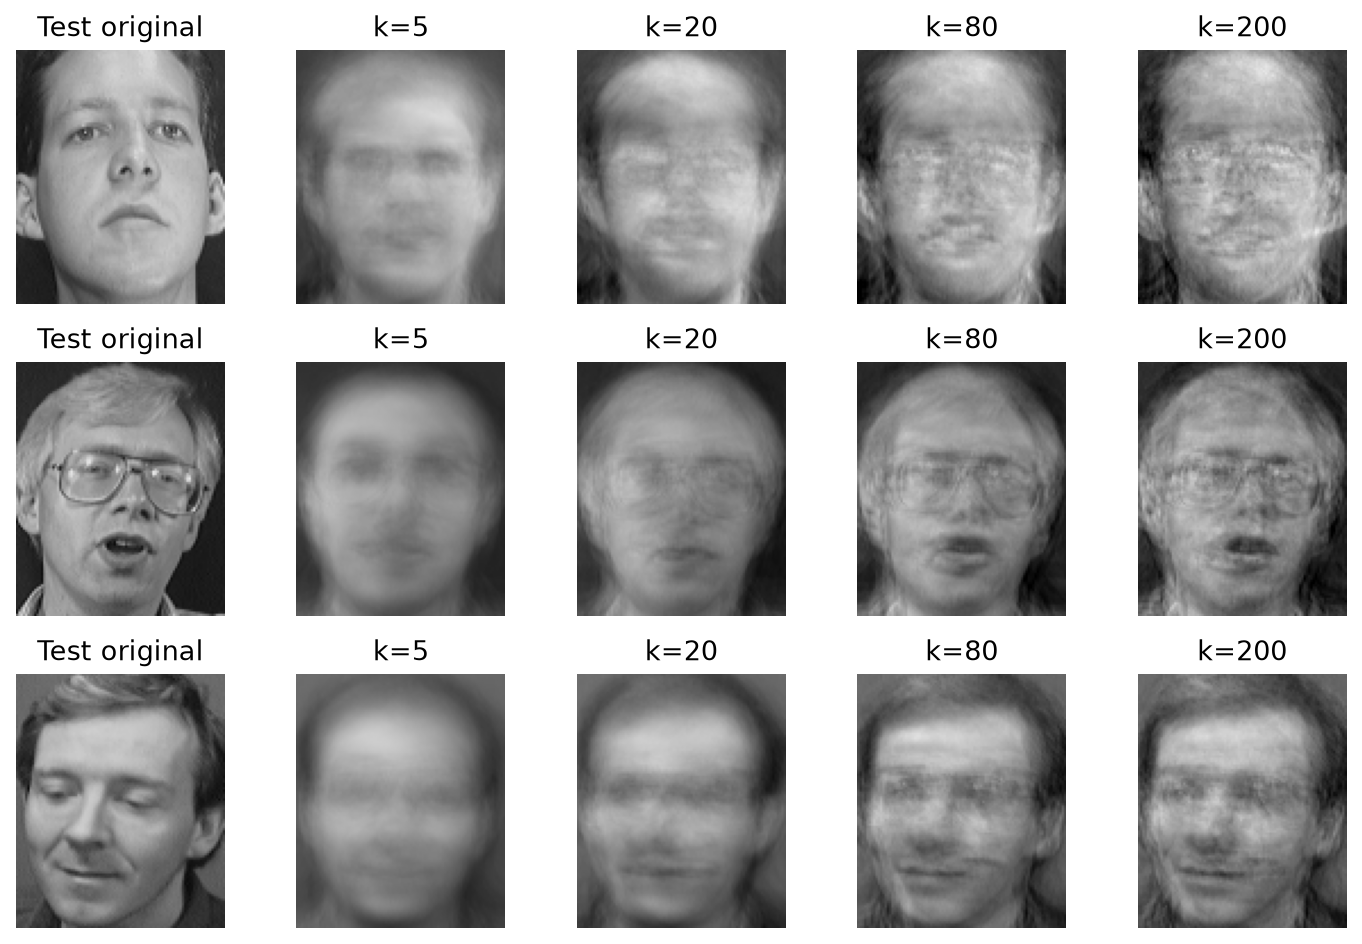

In [5]:
show_json("eigenfaces_summary.json")
show_image("07_eigenfaces_accuracy.png")
show_image("08_mean_eigenfaces.png")
show_image("09_face_reconstructions.png")

## 5. 量化与时序
量化使用真实 ORL 系数；时序轨迹是模拟，不是真实视频。

{'k': 32,
 'raw_frame_uint8_bytes': 10304,
 'coefficient_payload_bytes': 32,
 'shared_model_raw_bytes': 1360384,
 'shared_model_npz_bytes': 1362124,
 'basis_sha256': '0f0209f72081d0a0171a71b19bbd7f7ceab12350ea3ba6723e9141fb451f4755',
 'float_psnr_db': 21.44208937250024,
 'int8_psnr_db': 21.441347720104908,
 'psnr_loss_db': 0.0007416523953338583,
 'max_pixel_difference': 0.021110823541490187,
 'clipped_coefficient_fraction': 0.00234375,
 'int8_recognition_accuracy': 0.9666666666666667,
 'raw_payload_ratio': 322.0,
 'break_even_frames': 133,
 'first_120_frames_ratio': 0.9063614186526553}

{'source': 'synthetic smooth PCA coefficient trajectories, not real video',
 'frames': 300,
 'k': 32,
 'reset_interval': 60,
 'direct_int8_bytes': 9600,
 'delta_int16_bytes': 19200,
 'direct_zlib_bytes': 1979,
 'delta_zlib_bytes': 1387,
 'extra_factor_vs_direct_zlib': 1.426820475847152,
 'ratio_with_model_vs_raw_pixels': 2.2699851884053928}

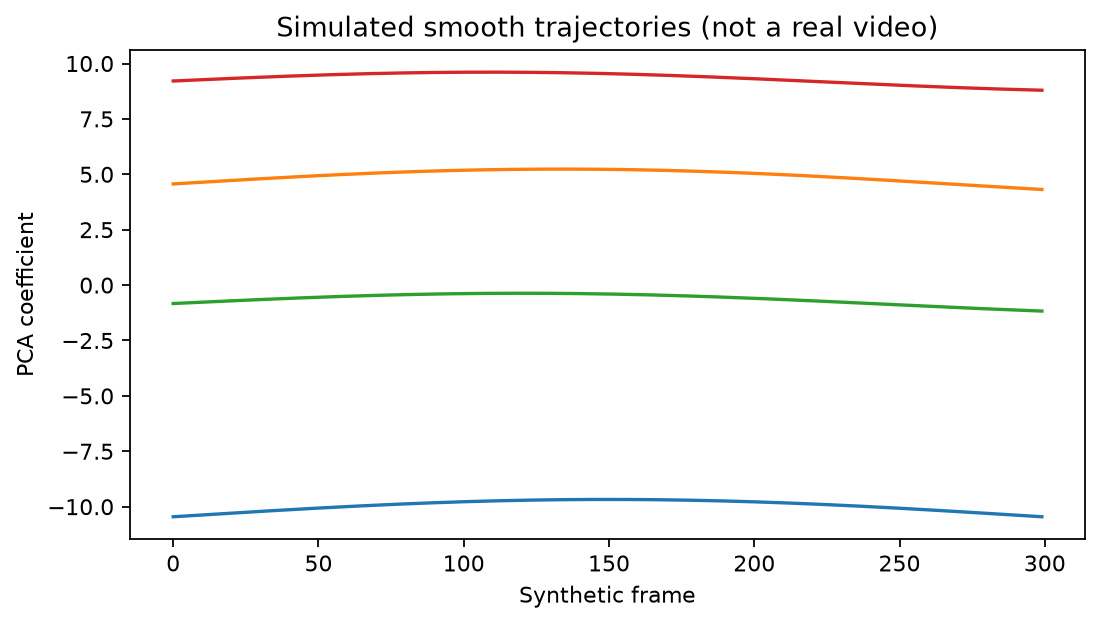

In [6]:
show_json("edge_quantization_summary.json")
show_json("temporal_summary.json")
show_image("10_synthetic_temporal_coefficients.png")

## 6. 3DMM教学替代
曲面为6模式合成数据，不是受试者三维扫描。

{'source': 'synthetic parametric surface, NOT real human scans or BFM',
 'train': 160,
 'test': 40,
 'vertices': 1280,
 'dimensions': 3840,
 'generative_modes': 6,
 'metrics': [{'k': 1, 'test_rmse': 0.03654624737582412},
  {'k': 2, 'test_rmse': 0.03130014231480125},
  {'k': 3, 'test_rmse': 0.022891687154748923},
  {'k': 5, 'test_rmse': 0.005568749028814002},
  {'k': 6, 'test_rmse': 5.36210758738794e-16}]}

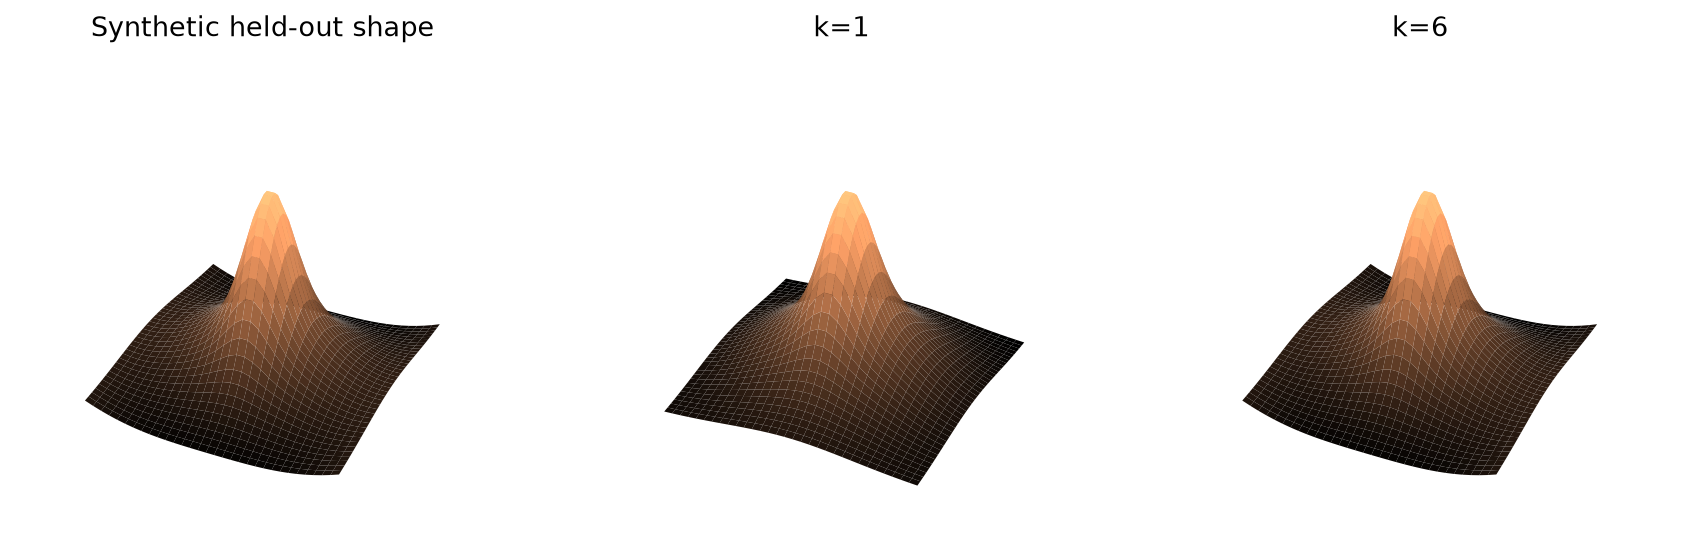

In [7]:
show_json("synthetic_3dmm_summary.json")
show_image("11_synthetic_3dmm.png")

## 7. 运行证据

In [8]:
show_json("run_summary.json")
show_json("verification.json")
assert all(json.loads((OUT/"verification.json").read_text()).values())

{'run_date': '2026-09-17',
 'seed': 20260917,
 'python': '3.13.7',
 'platform': 'macOS-27.0-arm64-arm-64bit-Mach-O',
 'numpy': '2.5.3',
 'scipy': '1.18.1',
 'matplotlib': '3.11.2',
 'pillow': '12.3.0',
 'elapsed_seconds': 2.270190715789795,
 'checks_passed': 22,
 'checks_total': 22}

{'matrix_matches_handout_rounding': True,
 'matrix_rank_4': True,
 'matrix_reconstruction': True,
 'right_eigenvector_equation': True,
 'left_eigenvector_equation': True,
 'eigen_implementation_singular_values': True,
 'image_tail_identity_k1': True,
 'image_tail_identity_k4': True,
 'image_tail_identity_k20': True,
 'image_tail_identity_k80': True,
 'image_tail_identity_k120': True,
 'image_tail_identity_k256': True,
 'image_tail_identity_k512': True,
 'image_metrics_monotonic': True,
 'image_full_rank_tail_zero': True,
 'faces_400_files': True,
 'faces_original_resolution': True,
 'no_train_test_overlap': True,
 'edge_saved_basis_decoding': True,
 'temporal_delta_lossless': True,
 'temporal_zlib_roundtrip': True,
 'synthetic_3dmm_rank6_reconstruction': True}